# PSF and higher-order moment maps for LSSTCam

Maps of the PSF shape (ellipticity, coma, trefoil, kurtosis) measured on the stars of a single LSSTCam visit,
shown both star by star and binned on a grid.

**How to use**
1. Set the visit to read in the *Input* cell (`BUTLER_REPO`, `DAY_OBS`, `SEQ_NUM`).
2. If needed, edit the *Settings* cell (output folders and figure options).
3. Run all the cells (`Run > Run All Cells`).

**Requirements**: the LSST Science Pipelines environment, plus the helper modules `ellipticity_util.py`
and `atmospheric_dispersion_correction.py` placed next to this notebook.

See the next cell for the description of the output files and their naming.

## Output files and nomenclature

In the file names, `<visit_id>` is the visit identifier (`DAY_OBS` without dashes followed by the 5-digit `SEQ_NUM`, e.g. `2026071300791`),
`<TAG>` is `OUTPUT_TAG`, and `<N>` is `N_GRID`.
"OCS" stands for Optical Coordinate System (columns and plots prefixed with `oc_`). "grid" in a name means that the
quantities are the median of the stars falling in each of the `N_GRID` x `N_GRID` cells (only cells with at least `N_MIN` stars).

### Tables (saved in `OUTPUT_DIR_TABLES`)

| File name | Format | Content |
|---|---|---|
| `stars_calib_psf_used<visit_id>_<TAG>.dat` | ASCII (astropy default) | One row per star flagged as `calib_psf_used` (the stars actually used for the PSF calculation). Columns: `coord_ra`, `coord_dec` (sky position), `base_PsfFlux_mag` (PSF-flux magnitude). |
| `statistics<visit_id>_<TAG>.dat` | ASCII (astropy default) | |
| `Moments_map_<visit_id>_<TAG>.dat` | CSV | One row per star, with the columns listed in `columns_to_print` (see the column table below). |
| `Moments_map_grid<N>x<N>_<visit_id>_<TAG>.dat` | CSV | One row per grid cell: median of the PSF moments in the cell, plus the higher moments computed from them. |

**Columns of `Moments_map_<visit_id>_<TAG>.dat`**

| Column | Description |
|---|---|
| `oc_field_x`, `oc_field_y` | |
| `oc_Ixx`, `oc_Ixy`, `oc_Iyy` | |
| `ext_shapeHSM_HigherOrderMomentsSource_30`, `_12`, `_21`, `_03` | Third-order moments (the two digits are the orders in x and y). |
| `ext_shapeHSM_HigherOrderMomentsSource_40`, `_04`, `_22` | Fourth-order moments (the two digits are the orders in x and y). |
| `T` | |
| `oc_e1`, `oc_e2` | |
| `e` | |
| `coma1`, `coma2` | |
| `trefoil1`, `trefoil2` | |
| `kurtosis` | |

### Figures (saved in `OUTPUT_DIR_FIGURES`, PDF)

All figures are titled with the `<visit_id>`.

| File name | Layout | Content |
|---|---|---|
| `Ellipticitymap_highermoments_OCS_<TAG>_<visit_id>.pdf` | 1 x 3 panels | Higher-order moments, star by star, in the OCS. Panels: |
| `Ellipticitymap_grid_highermoments_OCS_<TAG>_<visit_id>.pdf` | 1 x 3 panels | Same as above, from the gridded table. Panels: |
| `Ellipticitymap_OCS_<TAG>_<visit_id>.pdf` | 2 x 2 panels | Ellipticity map, star by star, in the OCS (at most `MAX_POINTS` stars drawn, arrow scale `SCALE_QUIVER`). Panels: |
| `Ellipticitymap_grid_OCS_<TAG>_<visit_id>.pdf` | 2 x 2 panels | Same as above, from the gridded table. Panels: |

## 1a. Input: image to read

In [2]:
# ========================= INPUT: IMAGE TO READ =========================
# Edit these three lines to choose the visit to analyse.

BUTLER_REPO = 'main'            # use 'embargo' for very recent images
DAY_OBS     = '2026-07-13'      # observing night, format 'YYYY-MM-DD'
SEQ_NUM     = 791               # exposure sequence number within that night
# =======================================================================

# Butler collections to read from.
# Note: the outputs in 'LSSTCam/prompt/output-<DAY_OBS>' do not have base_FPPosition.
COLLECTIONS = ['LSSTCam/runs/nightlyValidation']

# --- Advanced settings (normally no change needed) ---
OBJECT_TO_GET        = 'single_visit_star_footprints'  # dataset type of the per-detector star catalogs
VISIT_INFO_TO_GET    = 'preliminary_visit_image'       # dataset type used to read the filter and the visit information
FIRST_DET, N_DET     = 0, 189                          # first detector id and number of detectors to try to read (189 = all LSSTCam science detectors)
# =======================================================================

## 1b. Settings: output and figures

In [3]:
# ================= SETTINGS: DATA COLLECTIONS, OUTPUT AND FIGURES =================
# Normally only the output folder needs to be edited.

# --- Output ---
FOLDER_OUT_BASE = 'home/v/vittorio/image_quality_shared/imsim/ellipticitymap/' # Base destination folder of saved data
OUTPUT_DIR_FIGURES = FOLDER_OUT_BASE+'/figures/'   # subfolder where the figures (.pdf) are saved
OUTPUT_DIR_TABLES  = FOLDER_OUT_BASE+'/tables/'    # subfolder where the tables (.dat) are saved
OUTPUT_TAG = 'nightlyValidation_LSSTCam'   # label appended to all output file names

# --- Plot options ---
N_GRID       = 25      # the focal plane is divided into N_GRID x N_GRID cells for the gridded maps
N_MIN        = 3       # when calculating the median of moments on the N_GRID x N_GRID cells, only consider cells with at least N_MIN stars
SCALE_QUIVER = 0.75    # arrow scale of the star-by-star map (see makeOCSPlot)
MAX_POINTS   = 8000    # maximum number of stars drawn in the star-by-star map

## 2. Imports and set up

In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table, vstack
from astropy.io import ascii
from astropy.utils.metadata import MergeConflictWarning

from lsst.summit.extras.plotting.psfPlotting import makeAzElPlot, makeTableFromSourceCatalogs, makeFocalPlanePlot, makeEquatorialPlot, addColorbarToAxes
from lsst.obs.lsst import LsstComCam, LsstCam
from lsst.daf.butler import Butler
from lsst.daf.base import DateTime

from atmospheric_dispersion_correction import addADC_to_Table
from ellipticity_util import addFieldCoords_to_Table, makeOCSPlot, read_batoid_table, addOpticalCoords_to_Table, MakeGridMedianPSF, makeTableFromCalexps, statistics_on_moments, plotHigherOrderMomentsData, addHigherMoments

warnings.filterwarnings("ignore", category=MergeConflictWarning)

In [6]:
# Derived quantities (do not edit)
dayObs = int(DAY_OBS.replace('-', ''))
visit_id = int(f"{dayObs}{SEQ_NUM:05d}")   # visit identifier = dayObs followed by the 5-digit sequence number

# Create the output folders if they do not exist
os.makedirs(OUTPUT_DIR_FIGURES, exist_ok=True)
os.makedirs(OUTPUT_DIR_TABLES, exist_ok=True)

camera = LsstCam().getCamera()
butler = Butler(
    BUTLER_REPO,
    collections=COLLECTIONS,
    instrument="LSSTCam"
)

## 3. Read the star catalogs

In [7]:
# Read the star catalog of every detector; detectors that cannot be read are skipped
icSrcs = {}
detectors_found = []
for det in range(FIRST_DET, FIRST_DET + N_DET):
    try:
        icSrcs[det] = butler.get(OBJECT_TO_GET, dataId={"visit": visit_id, "detector": det})
        detectors_found.append(det)
    except Exception:
        print(det, 'not read')
        continue

if not detectors_found:
    raise RuntimeError(f"No detector could be read for visit {visit_id}: check BUTLER_REPO, COLLECTIONS, DAY_OBS and SEQ_NUM.")

# Read the filter band and the visit information (pointing, time, ...) from the first detector found
visitInfo = butler.get(VISIT_INFO_TO_GET, dataId={"visit": visit_id, "detector": detectors_found[0]})
band = visitInfo.getFilter().bandLabel
visitInfo = visitInfo.visitInfo

122 not read


## 4. Build the star table

In [8]:
# Merge the per-detector catalogs into a single table (one row per star)
table = makeTableFromSourceCatalogs(icSrcs, visitInfo)
# Tip: use table.colnames to list the available columns

In [9]:
# Append the higher moments (third- and fourth-order) to the table
table = addHigherMoments(table)

In [10]:
# Add atmospheric dispersion correction to the table
elevation_angle = visitInfo.boresightAzAlt[1].asDegrees()  # elevation angle in degrees
table = addADC_to_Table(table, elevation_angle, band)      # optional pressure and temperature arguments

In [11]:
# Convert coordinates and moments to the Optical Coordinate System
table = addOpticalCoords_to_Table(table)
table = addFieldCoords_to_Table(table, camera)

In [12]:
# Save the position and magnitude of the stars flagged as "calib_psf_used" (those actually used for the calculation of the PSF)
table2 = table[table['calib_psf_used']]['coord_ra', 'coord_dec', 'base_PsfFlux_mag']
ascii.write(table2, OUTPUT_DIR_TABLES + 'stars_calib_psf_used' + str(visit_id) + '_' + OUTPUT_TAG + '.dat', overwrite=True)

## 5. Gridded table and statistics

In [13]:
# Add to the table the the median of the PSF moments on a N_GRID x N_GRID table
table_grid = MakeGridMedianPSF(table, N_GRID, N_GRID, N_MIN)
table_grid = addHigherMoments(table_grid)

In [14]:
# Statistics on moments
statistics = statistics_on_moments(table)

ascii.write(statistics, OUTPUT_DIR_TABLES + 'statistics' + str(visit_id) + '_' + OUTPUT_TAG + '.dat', overwrite=True)

## 6. Save the moment tables

In [16]:
# Columns of the star table that are written to the output file
columns_to_print = ['oc_field_x',
                    'oc_field_y',
                    'oc_Ixx',
                    'oc_Ixy',
                    'oc_Iyy',
                    'ext_shapeHSM_HigherOrderMomentsSource_30',
                    'ext_shapeHSM_HigherOrderMomentsSource_12',
                    'ext_shapeHSM_HigherOrderMomentsSource_21',
                    'ext_shapeHSM_HigherOrderMomentsSource_03',
                    'ext_shapeHSM_HigherOrderMomentsSource_40',
                    'ext_shapeHSM_HigherOrderMomentsSource_04',
                    'ext_shapeHSM_HigherOrderMomentsSource_22',
                    'T',
                    'oc_e1',
                    'oc_e2',
                    'e',
                    'coma1',
                    'coma2',
                    'trefoil1',
                    'trefoil2',
                    'kurtosis']

In [17]:
# Write the star table and the gridded table to CSV-formatted files
table[columns_to_print].write(OUTPUT_DIR_TABLES + 'Moments_map_' + str(visit_id) + '_' + OUTPUT_TAG + '.csv', format="csv", overwrite=True)
table_grid.write(OUTPUT_DIR_TABLES + 'Moments_map_grid' + str(N_GRID) + 'x' + str(N_GRID) + '_' + str(visit_id) + '_' + OUTPUT_TAG + '.csv', format="csv", overwrite=True)

## 7. Plots

### Higher-order moments: star by star

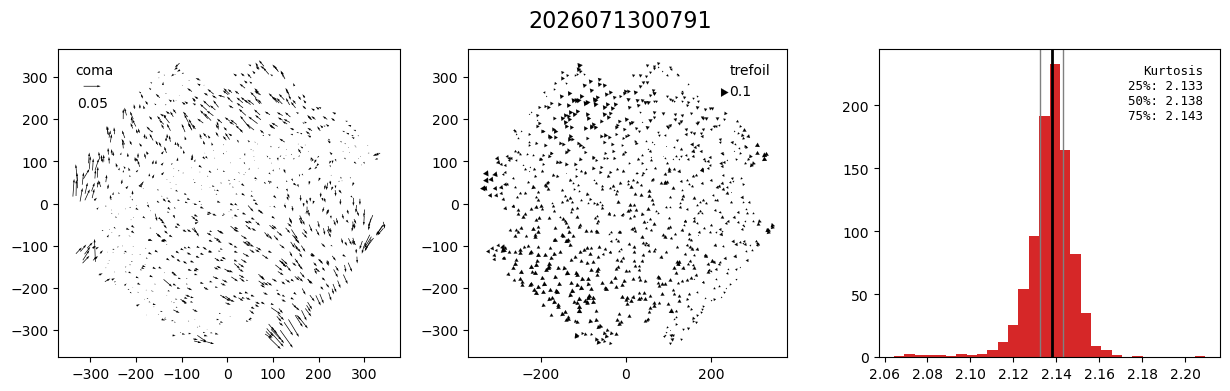

In [18]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
fig.suptitle(visit_id, fontsize=16)
plotHigherOrderMomentsData(fig, axes, table, prefix='oc_')
plt.show()
fig.savefig(OUTPUT_DIR_FIGURES + 'Ellipticitymap_highermoments_OCS_' + OUTPUT_TAG + '_' + str(visit_id) + '.pdf')

### Higher-order moments: gridded

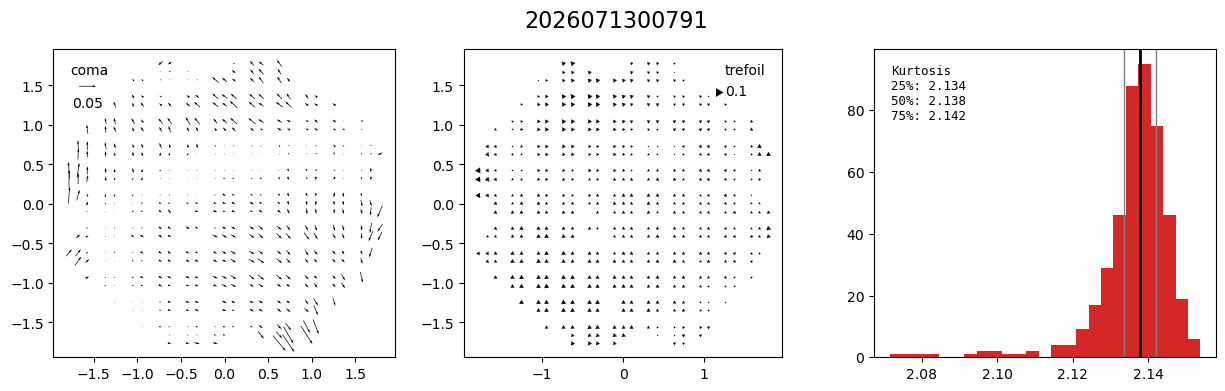

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
fig.suptitle(visit_id, fontsize=16)
plotHigherOrderMomentsData(fig, axes, table_grid, prefix='oc_field_', is_grid=True)
plt.show()
fig.savefig(OUTPUT_DIR_FIGURES + 'Ellipticitymap_grid_highermoments_OCS_' + OUTPUT_TAG + '_' + str(visit_id) + '.pdf')

### Ellipticity map: star by star

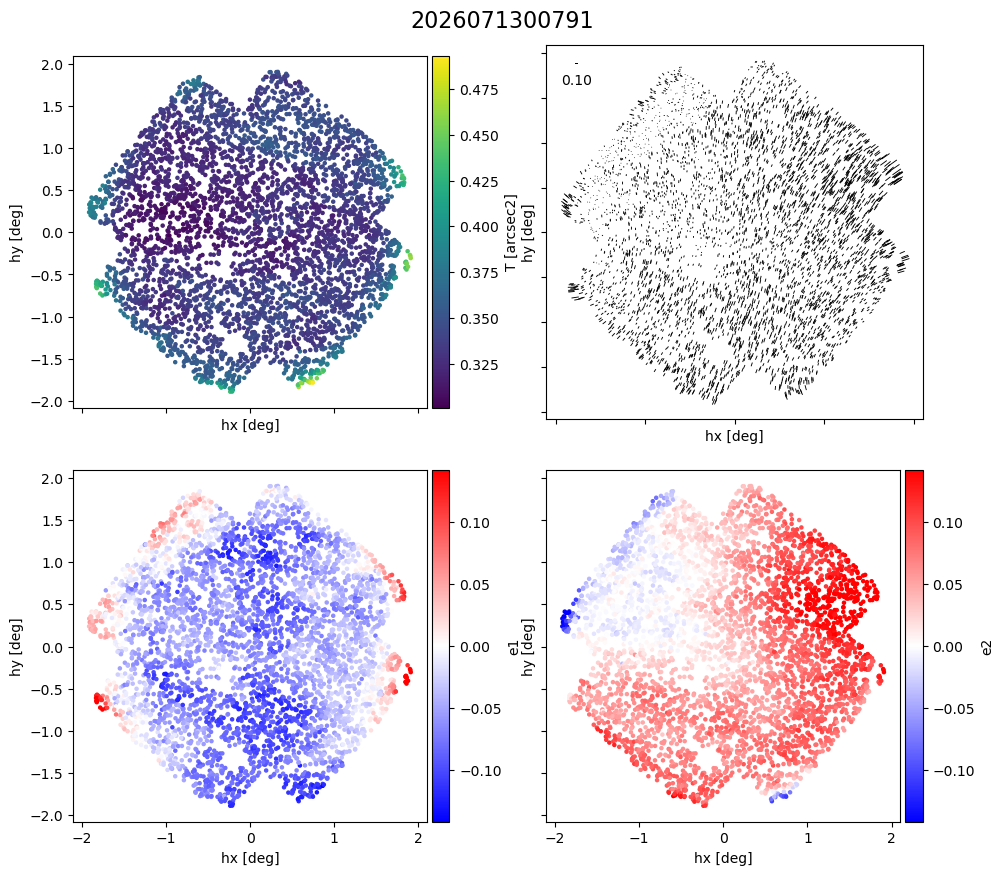

In [20]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 9), sharex=True, sharey=True)
fig.suptitle(visit_id, fontsize=16)
makeOCSPlot(fig, axes, table, camera, autoscale=True, scale_quiver=SCALE_QUIVER, maxPoints=MAX_POINTS, coords='oc')
plt.show()
fig.savefig(OUTPUT_DIR_FIGURES + 'Ellipticitymap_OCS_' + OUTPUT_TAG + '_' + str(visit_id) + '.pdf')

### Ellipticity map: gridded

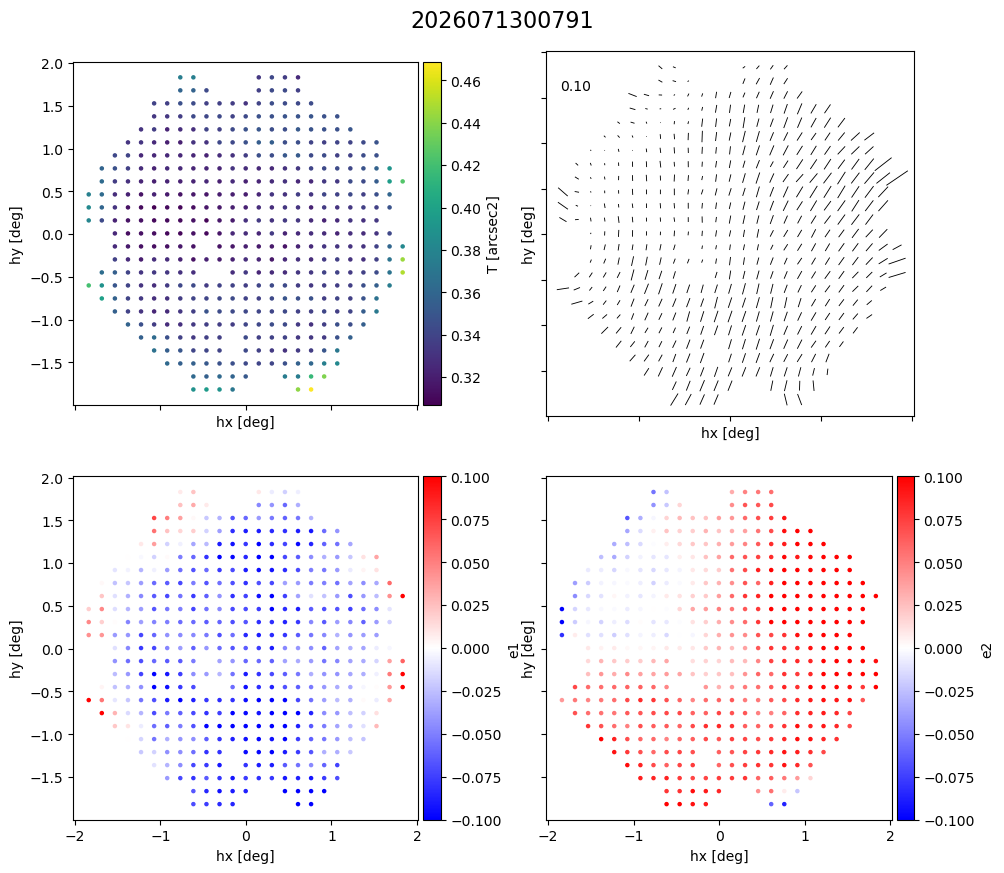

In [21]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 9), sharex=True, sharey=True)
fig.suptitle(visit_id, fontsize=16)
makeOCSPlot(fig, axes, table_grid, camera, coords='oc')
plt.show()
fig.savefig(OUTPUT_DIR_FIGURES + 'Ellipticitymap_grid_OCS_' + OUTPUT_TAG + '_' + str(visit_id) + '.pdf')